# Ejercicio 2 — YOLO11n: confianza y NMS

Detección sin entrenamiento. Imagen: `data/crowd.jpg`, convertida desde `shutterstock_86973980.l.webp`, facilitada desde Downloads (Shutterstock; comprobar licencia antes de redistribuirla). Modelo: [yolo11n.pt, pesos oficiales](https://github.com/ultralytics/assets/releases/download/v8.3.0/yolo11n.pt). Se utilizan los archivos locales, sin descarga automática.

Ejecutar con el intérprete `.venv` de **este ejercicio**, no el entorno compartido. En Jupyter, seleccionar un kernel que apunte a `ejercicios/02_yolo/.venv/Scripts/python.exe`. Si se ejecuta desde la raíz del proyecto se detecta la carpeta automáticamente.

In [1]:
from pathlib import Path
import os
import sys

cwd = Path.cwd().resolve()
ROOT = cwd if (cwd / 'yolo.ipynb').exists() else cwd / 'ejercicios' / '02_yolo'
assert (ROOT / 'yolo.ipynb').is_file(), f'No se encuentra el ejercicio desde {cwd}'
for folder in ('data', 'models', 'outputs'):
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
os.environ['YOLO_CONFIG_DIR'] = str(ROOT / 'outputs' / 'ultralytics_config')
os.environ['MPLCONFIGDIR'] = str(ROOT / 'outputs' / 'matplotlib_config')
import torch
import ultralytics
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2

device = 0 if torch.cuda.is_available() else 'cpu'
print(f'Python: {sys.executable} | Ultralytics: {ultralytics.__version__} | Torch: {torch.__version__} | dispositivo: {device}')

Python: C:\Users\steve\Desktop\Examen_EU4_CV\ejercicios\02_yolo\.venv\Scripts\python.exe | Ultralytics: 8.4.202 | Torch: 2.15.0+cpu | dispositivo: cpu


## Imagen y pesos locales

Modelo disponible: C:\Users\steve\Desktop\Examen_EU4_CV\ejercicios\02_yolo\models\yolo11n.pt | bytes: 5613764


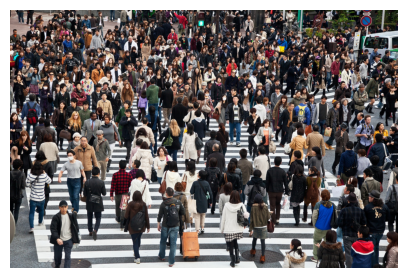

In [2]:
image = ROOT / 'data' / 'crowd.jpg'
weights = ROOT / 'models' / 'yolo11n.pt'
for path in (image, weights):
    if not path.is_file() or path.stat().st_size == 0:
        raise FileNotFoundError(f'Archivo local ausente o vacío: {path}')
print('Modelo disponible:', weights, '| bytes:', weights.stat().st_size)
img = cv2.imread(str(image))
assert img is not None, f'No se pudo leer {image}'
plt.figure(figsize=(5, 6)); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); plt.axis('off'); plt.show()
model = YOLO(str(weights))

## Baseline y barrido de parámetros

Mantenemos la imagen, el tamaño de entrada y el dispositivo constantes. El baseline es `conf=0.25, iou=0.50`. No hay etiquetas de referencia: el número de detecciones **no** mide precisión ni recall.

In [3]:
# conf: umbral mínimo de confianza para conservar una detección.
# iou: umbral de solapamiento entre cajas utilizado por NMS para suprimir
# cajas redundantes de la misma clase; no es IoU contra ground truth.
def infer(conf, iou):
    return model.predict(source=str(image), conf=conf, iou=iou, imgsz=640,
                         device=device, verbose=False, save=False)[0]

baseline = infer(0.25, 0.50)
print('Baseline: conf=0.25, iou=0.50; detecciones:', len(baseline.boxes))
results = {(0.25, 0.50): baseline}
for conf, iou in [(0.10, 0.50), (0.50, 0.50), (0.25, 0.30), (0.25, 0.70)]:
    results[(conf, iou)] = infer(conf, iou)
for (conf, iou), result in results.items():
    print(f'conf={conf:.2f} iou={iou:.2f}: {len(result.boxes)} detecciones')

Baseline: conf=0.25, iou=0.50; detecciones: 16


conf=0.25 iou=0.50: 16 detecciones
conf=0.10 iou=0.50: 37 detecciones
conf=0.50 iou=0.50: 7 detecciones
conf=0.25 iou=0.30: 16 detecciones
conf=0.25 iou=0.70: 16 detecciones


## Comparaciones visuales

Con `conf` mayor se descartan candidatos de menor confianza. Un IoU de NMS mayor suele permitir más cajas solapadas, pero puede no cambiar nada en una imagen concreta.

{'conf': 0.1, 'iou_nms': 0.5, 'detecciones': 37, 'clases': "{'person': 30, 'suitcase': 1, 'backpack': 2, 'truck': 1, 'handbag': 3}", 'conf_min': 0.1023988127708435, 'conf_max': 0.7215262651443481}
{'conf': 0.25, 'iou_nms': 0.3, 'detecciones': 16, 'clases': "{'person': 14, 'suitcase': 1, 'backpack': 1}", 'conf_min': 0.2736301124095917, 'conf_max': 0.7215262651443481}
{'conf': 0.25, 'iou_nms': 0.5, 'detecciones': 16, 'clases': "{'person': 14, 'suitcase': 1, 'backpack': 1}", 'conf_min': 0.2736301124095917, 'conf_max': 0.7215262651443481}
{'conf': 0.25, 'iou_nms': 0.7, 'detecciones': 16, 'clases': "{'person': 14, 'suitcase': 1, 'backpack': 1}", 'conf_min': 0.2736301124095917, 'conf_max': 0.7215262651443481}
{'conf': 0.5, 'iou_nms': 0.5, 'detecciones': 7, 'clases': "{'person': 6, 'suitcase': 1}", 'conf_min': 0.5382600426673889, 'conf_max': 0.7215262651443481}


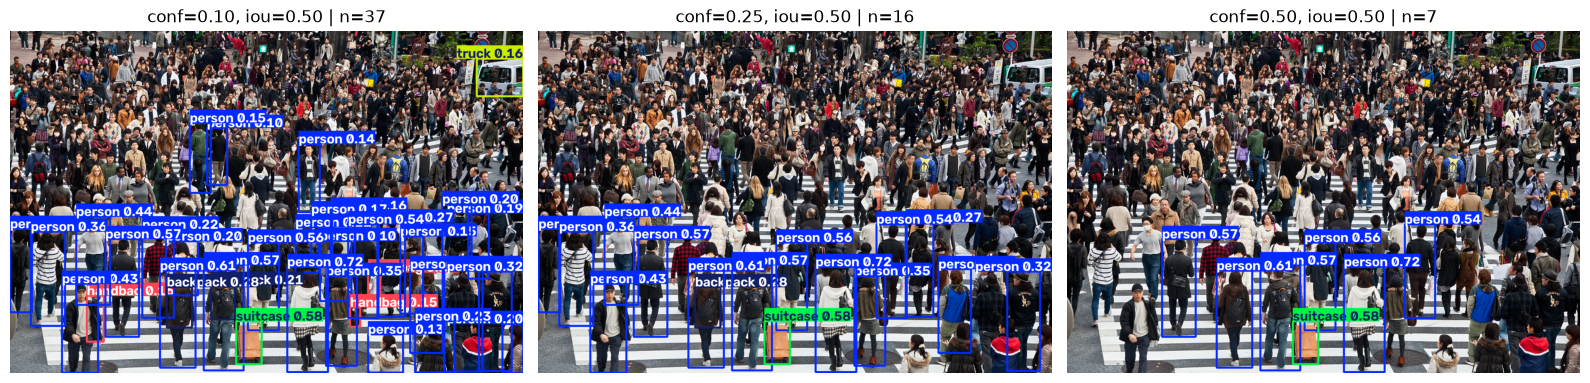

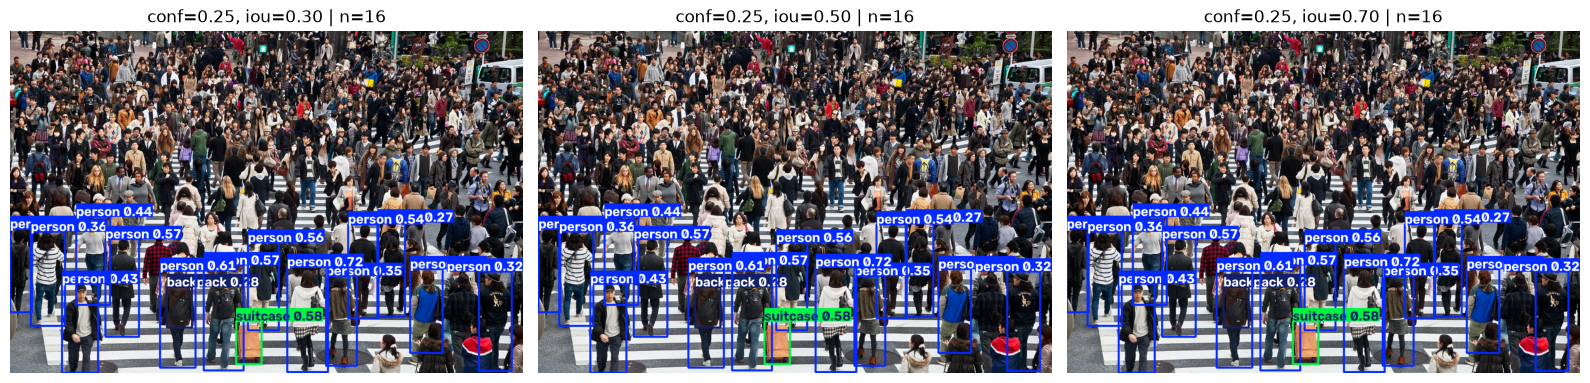

In [4]:
import csv
from collections import Counter
rows = []
for (c, i), r in sorted(results.items()):
    clases = Counter(r.names[int(cls)] for cls in r.boxes.cls.cpu().tolist())
    scores = r.boxes.conf.cpu().tolist()
    rows.append({'conf': c, 'iou_nms': i, 'detecciones': len(r.boxes),
                 'clases': str(dict(clases)), 'conf_min': min(scores, default=None),
                 'conf_max': max(scores, default=None)})
with (ROOT / 'outputs' / 'detecciones.csv').open('w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=['conf', 'iou_nms', 'detecciones', 'clases', 'conf_min', 'conf_max'])
    writer.writeheader(); writer.writerows(rows)
for row in rows:
    print(row)

def comparar(configs, filename):
    fig, axes = plt.subplots(1, 3, figsize=(16, 8))
    for ax, (c, i) in zip(axes, configs):
        r = results[(c, i)]
        # result.plot devuelve BGR; Matplotlib necesita RGB.
        ax.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB))
        ax.set_title(f'conf={c:.2f}, iou={i:.2f} | n={len(r.boxes)}')
        ax.axis('off')
    fig.tight_layout()
    fig.savefig(ROOT / 'outputs' / filename, dpi=140, bbox_inches='tight')
    plt.show()

comparar([(0.10, 0.50), (0.25, 0.50), (0.50, 0.50)], 'comparacion_conf.png')
comparar([(0.25, 0.30), (0.25, 0.50), (0.25, 0.70)], 'comparacion_iou.png')

In [5]:
# Compara también cajas, clases y confianzas, no solo el número de cajas.
def firma(r):
    return sorted(tuple(round(float(v), 4) for v in row) for row in r.boxes.data.cpu().tolist())
same = firma(results[(0.25, 0.30)]) == firma(results[(0.25, 0.50)]) == firma(results[(0.25, 0.70)])
print('Resultados idénticos para los tres valores de IoU:', same)
if same:
    print('En esta imagen, el cambio de IoU no alteró las cajas finales; ninguna diferencia de supresión afectó al resultado final en ese intervalo.')
else:
    print('Al variar IoU cambió al menos una caja, clase o confianza; revisar la comparación visual.')
for (c, i), r in sorted(results.items()):
    base = results[(0.25, 0.50)]
    actual, ref = set(firma(r)), set(firma(base))
    print(f'conf={c:.2f}, iou={i:.2f}: {len(actual-ref)} cajas nuevas y {len(ref-actual)} ausentes frente al baseline (comparación exacta redondeada a 4 decimales)')
print('Conteos guardados en', ROOT / 'outputs' / 'detecciones.csv')

Resultados idénticos para los tres valores de IoU: True
En esta imagen, el cambio de IoU no alteró las cajas finales; ninguna diferencia de supresión afectó al resultado final en ese intervalo.
conf=0.10, iou=0.50: 21 cajas nuevas y 0 ausentes frente al baseline (comparación exacta redondeada a 4 decimales)
conf=0.25, iou=0.30: 0 cajas nuevas y 0 ausentes frente al baseline (comparación exacta redondeada a 4 decimales)
conf=0.25, iou=0.50: 0 cajas nuevas y 0 ausentes frente al baseline (comparación exacta redondeada a 4 decimales)
conf=0.25, iou=0.70: 0 cajas nuevas y 0 ausentes frente al baseline (comparación exacta redondeada a 4 decimales)
conf=0.50, iou=0.50: 0 cajas nuevas y 9 ausentes frente al baseline (comparación exacta redondeada a 4 decimales)
Conteos guardados en C:\Users\steve\Desktop\Examen_EU4_CV\ejercicios\02_yolo\outputs\detecciones.csv


## Conclusión

La comparación es descriptiva para una sola imagen. El IoU de NMS controla supresión de predicciones redundantes y no debe confundirse con IoU de evaluación frente a anotaciones. Sin ground truth no se puede afirmar que una configuración sea más precisa.